# Prompt format vs. token usage: exploratory analysis

**Research question:** Does prompt format (structured vs. informal) affect token usage when an LLM writes Python code for the same requirements?

- **Independent variable:** `format`, either `structured` (labeled sections, bulleted requirements) or `informal` (one casual paragraph)
- **Dependent variables:** `input_tokens`, `output_tokens` (token counts reported by the model with every response)
- **Secondary check:** hidden unit tests passed (one test per requirement)
- **Controls:** same model, temperature, `max_tokens`, and system prompt on every call; no prompt caching; no extended thinking

**Unit of analysis.** Each task has 5 runs per format, but those runs are repeated measurements of the *same* prompt, not independent samples. Statistical tests therefore compare **per-task means** (10 pairs). Treating all 100 rows as independent would overstate certainty (pseudo-replication).

> The "How to read it" notes below explain each plot. Lines marked **Result:** describe the run in `data/results.csv` (`qwen2.5-coder:7b` via Ollama, 100 calls, collected 2026-10-14). If you re-run the experiment, re-check them against the new numbers.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

SEED = 42
RESULTS_CSV = "../data/results.csv"
MODEL = "qwen2.5-coder:7b"   # analyze one model at a time (must match config.py)

FORMATS = ["structured", "informal"]
COLORS = {"structured": "#2a78d6", "informal": "#eb6834"}  # blue / orange (colorblind-safe pair)
NEUTRAL = "#8a8984"

plt.rcParams.update({
    "figure.dpi": 110,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.edgecolor": "#b5b4ae",
    "axes.grid": True,
    "grid.color": "#e6e5e0",
    "grid.linewidth": 0.8,
    "axes.axisbelow": True,
    "font.size": 10,
})

df = pd.read_csv(RESULTS_CSV)
df = df[df["model"] == MODEL].copy()
df["pass_rate"] = df["tests_passed"] / df["tests_total"]
print(f"{len(df)} rows for {MODEL}")
df.head()

100 rows for qwen2.5-coder:7b


,task_id,format,run,model,input_tokens,output_tokens,tests_passed,tests_total,passed_all,stop_reason,timestamp,pass_rate
0,t05_roman,structured,3,qwen2.5-coder:7b,231,222,5,5,True,stop,2026-10-14T03:51:04+00:00,1.000000
1,t05_roman,structured,2,qwen2.5-coder:7b,231,173,5,5,True,stop,2026-10-14T03:51:07+00:00,1.000000
2,t10_lru_cache,structured,2,qwen2.5-coder:7b,281,170,8,8,True,stop,2026-10-14T03:51:11+00:00,1.000000
3,t01_fizzbuzz,informal,5,qwen2.5-coder:7b,155,72,5,5,True,stop,2026-10-14T03:51:12+00:00,1.000000
4,t07_duration,informal,1,qwen2.5-coder:7b,280,166,4,6,False,stop,2026-10-14T03:51:16+00:00,0.666667


## 0. The tasks

Everything below is read straight from the `tasks/` folder, so it always matches the prompts the model actually received. Change `EXAMPLE_TASK` to view a different pair.

In [2]:
import html
import re
import textwrap
from pathlib import Path
from IPython.display import HTML, Markdown

TASKS_DIR = Path("../tasks")
EXAMPLE_TASK = "t04_password"

def read_task_file(task_id, name):
    return (TASKS_DIR / task_id / name).read_text(encoding="utf-8")

def wrapped(text, width=76):
    """Wrap long lines so the prompts fit side by side (keeps the original line breaks)."""
    return "\n".join(textwrap.fill(line, width) if line else "" for line in text.splitlines())

columns = "".join(
    f'<td style="vertical-align:top; padding:0 12px"><b>{fmt}.txt</b>'
    f'<pre style="white-space:pre-wrap">{html.escape(wrapped(read_task_file(EXAMPLE_TASK, fmt + ".txt")))}</pre></td>'
    for fmt in FORMATS
)
display(Markdown(f"### Example: `{EXAMPLE_TASK}`, both prompts"))
display(HTML(f"<table><tr>{columns}</tr></table>"))

### Example: `t04_password`, both prompts

"structured.txt## Goal Write a function that checks whether a password is strong. ## Input `validate_password(pw: str) -> bool` ## Requirements 1. The password must be at least 8 characters long. 2. It must contain at least one uppercase letter. 3. It must contain at least one lowercase letter. 4. It must contain at least one digit. 5. It must contain at least one of these special characters: ! @ # $ % 6. It must not contain any spaces. ## Output Return True if every requirement is met, otherwise False. Respond with only Python code.","informal.txtHey, can you write me a little Python function called validate_password(pw) that tells me whether a password is good enough? It should give back True if it passes every rule, otherwise False. Spaces aren't allowed anywhere in it, and it needs at least one digit in there somewhere. Oh, and it has to be at least 8 characters long. I also want at least one uppercase letter and at least one lowercase letter, plus at least one of the special characters ! @ # $ or %. Just send back the Python code, nothing else."


In [3]:
# The checklist maps every requirement to where it appears in each prompt, and to its hidden test.
display(Markdown(read_task_file(EXAMPLE_TASK, "checklist.md")))

# t04_password checklist

| Req | Requirement | Structured | Informal (quoted phrase) | Test |
|---|---|---|---|---|
| R1 | length >= 8 | Requirements #1 | "it has to be at least 8 characters long" | `test_r1_min_length` |
| R2 | >= 1 uppercase | Requirements #2 | "at least one uppercase letter" | `test_r2_uppercase` |
| R3 | >= 1 lowercase | Requirements #3 | "at least one lowercase letter" | `test_r3_lowercase` |
| R4 | >= 1 digit | Requirements #4 | "it needs at least one digit in there somewhere" | `test_r4_digit` |
| R5 | >= 1 of ! @ # $ % | Requirements #5 | "at least one of the special characters ! @ # $ or %" | `test_r5_special_character` |
| R6 | no spaces | Requirements #6 | "Spaces aren't allowed anywhere in it" | `test_r6_no_spaces` |

Shared by both prompts: name `validate_password(pw)`, returns True/False, "only Python code".


**How to read it:** both prompts ask for exactly the same function and the same requirements, so only the presentation differs. The structured version uses labeled sections and a numbered list. The informal version is one conversational paragraph, with the requirements in a different order. The checklist shows where each requirement (R1, R2, …) appears in both, which is how we confirm neither prompt asks for more than the other.

### All 10 tasks

In [4]:
task_rows = []
for task_dir in sorted(p for p in TASKS_DIR.glob("t*") if p.is_dir()):
    task_id = task_dir.name
    structured = read_task_file(task_id, "structured.txt")
    informal = read_task_file(task_id, "informal.txt")
    task_rows.append({
        "task_id": task_id,
        # same counting rules as src/check_tasks.py: requirement rows in the checklist, test functions
        "requirements": len(re.findall(r"^\| R\d+ \|", read_task_file(task_id, "checklist.md"), re.MULTILINE)),
        "tests": len(re.findall(r"^def test_", read_task_file(task_id, "test_solution.py"), re.MULTILINE)),
        "structured words": len(structured.split()),
        "informal words": len(informal.split()),
    })
tasks_table = pd.DataFrame(task_rows).set_index("task_id")

# Prompt length in tokens, as the model counted it (includes the system prompt; identical on every run).
prompt_tokens = df.groupby(["task_id", "format"])["input_tokens"].mean().unstack()[FORMATS].round(0).astype(int)
tasks_table["structured input tokens"] = prompt_tokens["structured"]
tasks_table["informal input tokens"] = prompt_tokens["informal"]
tasks_table.loc["total"] = tasks_table.sum()
tasks_table

,requirements,tests,structured words,informal words,structured input tokens,informal input tokens
task_id,,,,,,
t01_fizzbuzz,5,5,112,96,189,155
t02_whitespace,4,4,90,104,144,154
t03_chunk,5,5,106,106,176,153
t04_password,6,6,95,95,148,137
t05_roman,5,5,105,100,231,217
t06_wordfreq,6,6,138,135,224,201
t07_duration,6,6,172,166,310,280
t08_intervals,6,6,126,123,221,197
t09_transactions,7,7,164,149,271,231


**How to read it:** `requirements` should equal `tests` in every row, because each requirement has exactly one hidden test (58 in total). The word counts measure the prompt text itself. The input-token columns are the length as the model counted it, including the short system prompt that's the same for every call. 

**Result:** the two formats use almost the same number of words (1,271 vs 1,246 in total, and identical in `t03` and `t04`). Yet the structured prompt takes more tokens in 9 of 10 tasks (2,195 vs 1,979 in total). In `t10_lru_cache` the informal prompt has *more* words (172 vs 163) but still *fewer* tokens (254 vs 281). So the extra input tokens come from formatting, not wording: the `##` headings, numbered list markers, backticks and line breaks each cost tokens. Section 5 checks whether this length gap could explain the difference in output tokens.

## 1. Sanity checks

In [5]:
print("Runs per task x format (every cell should equal N_RUNS):")
display(df.pivot_table(index="task_id", columns="format", values="run", aggfunc="count"))

print("stop_reason counts ('length' or 'max_tokens' would mean a truncated answer):")
display(df["stop_reason"].value_counts())

print("Missing values per column:")
display(df.isna().sum()[lambda s: s > 0] if df.isna().any().any() else "none")

Runs per task x format (every cell should equal N_RUNS):


format,informal,structured
task_id,,
t01_fizzbuzz,5,5
t02_whitespace,5,5
t03_chunk,5,5
t04_password,5,5
t05_roman,5,5
t06_wordfreq,5,5
t07_duration,5,5
t08_intervals,5,5
t09_transactions,5,5


stop_reason counts ('length' or 'max_tokens' would mean a truncated answer):


stop_reason
stop    100
Name: count, dtype: int64

Missing values per column:


'none'

**How to read it:** every task × format cell should show the same count (N_RUNS). A `length` (Ollama) or `max_tokens` (Claude) stop reason means a response was cut off, and its `output_tokens` is capped, not natural. Investigate those rows before trusting the token comparisons.

**Result:** all 100 rows are present (5 per task × format), every response ended normally (`stop`), and nothing is missing. No answer was cut off, so the output-token counts are natural lengths.

## 2. Summary table: tokens by format

In [6]:
summary = df.groupby("format")[["input_tokens", "output_tokens"]].agg(["mean", "median", "std"]).round(1)
summary.loc[FORMATS]

input_tokens              output_tokens             
                   mean median   std          mean median   std
format                                                         
structured        219.5  222.5  53.8         143.0  155.5  60.1
informal          197.9  199.0  46.1         126.9  118.0  62.7

**How to read it:** this table pools all tasks and runs, so it's a first look and not the test. Compare the means and medians between rows. A big gap between mean and median suggests a few long responses are pulling the mean.

**Result:** informal prompts were shorter to send (mean 197.9 vs 219.5 input tokens) and got shorter answers (mean 126.9 vs 143.0 output tokens; median 118 vs 155.5). The standard deviations (~60 output tokens) are much bigger than the gap, because tasks differ a lot in size. That's why the paired comparison below matters.

## 3. Distribution of output tokens by format

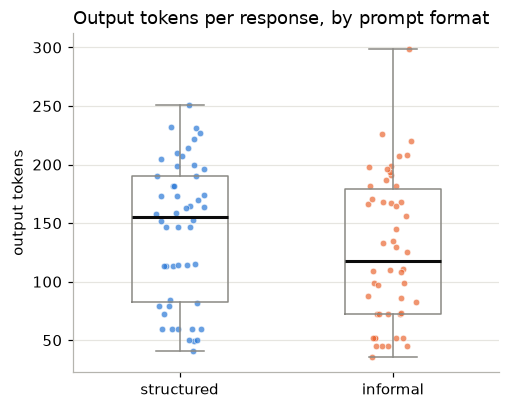

In [7]:
fig, ax = plt.subplots(figsize=(5, 4))
data = [df.loc[df["format"] == f, "output_tokens"] for f in FORMATS]
ax.boxplot(data, tick_labels=FORMATS, widths=0.45, showfliers=False,
           medianprops={"color": "#0b0b0b", "linewidth": 2},
           boxprops={"color": NEUTRAL}, whiskerprops={"color": NEUTRAL}, capprops={"color": NEUTRAL})
rng = np.random.default_rng(SEED)
for i, (f, values) in enumerate(zip(FORMATS, data), start=1):
    jitter = rng.uniform(-0.12, 0.12, size=len(values))
    ax.scatter(i + jitter, values, s=18, color=COLORS[f], alpha=0.7, edgecolor="white", linewidth=0.5)
ax.set_ylabel("output tokens")
ax.set_title("Output tokens per response, by prompt format", loc="left")
ax.grid(axis="x", visible=False)
plt.show()

**How to read it:** the box spans the middle 50% of responses and the black line is the median. Each dot is one response. Shifted or differently sized boxes suggest format matters, but tasks differ a lot in how much code they need, so this pooled view mixes task difficulty with format. Section 4 controls for that.

**Result:** the informal box sits somewhat lower (median 118 vs 155.5), but the two distributions overlap heavily. On its own this plot can't separate format from task size.

## 4. Paired comparison per task (slope plot)

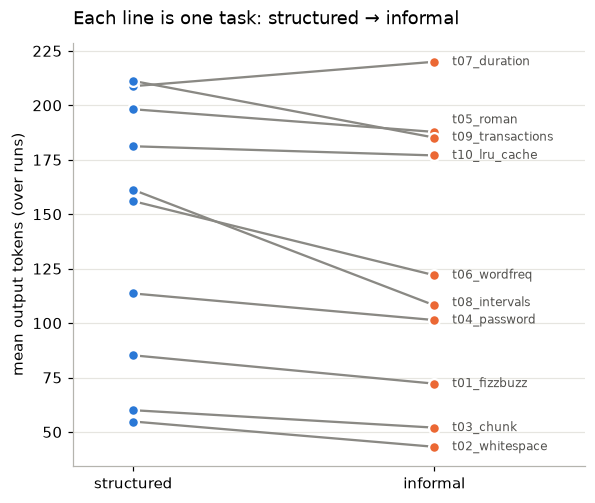

Tasks where informal used MORE output tokens: 1 of 10


In [8]:
task_means = df.groupby(["task_id", "format"])[["input_tokens", "output_tokens", "pass_rate"]].mean().unstack()
out = task_means["output_tokens"][FORMATS]

fig, ax = plt.subplots(figsize=(6, 5))
for task_id, row in out.iterrows():
    ax.plot([0, 1], [row["structured"], row["informal"]], color=NEUTRAL, linewidth=1.5, zorder=1)
for x, f in enumerate(FORMATS):
    ax.scatter([x] * len(out), out[f], s=50, color=COLORS[f], edgecolor="white", linewidth=1.5, zorder=2)

# Task labels at the right end, nudged apart so close values don't overlap.
min_gap = (out.values.max() - out.values.min()) * 0.045
label_y = None
for task_id, y in out["informal"].sort_values().items():
    label_y = y if label_y is None else max(y, label_y + min_gap)
    ax.text(1.06, label_y, task_id, va="center", fontsize=8, color="#52514e")
ax.set_ylim(top=max(ax.get_ylim()[1], label_y + min_gap))  # keep the top label inside the plot

ax.set_xticks([0, 1], FORMATS)  # the x-axis names the formats, so no legend is needed
ax.set_xlim(-0.2, 1.5)
ax.set_ylabel("mean output tokens (over runs)")
ax.set_title("Each line is one task: structured → informal", loc="left", pad=12)
ax.grid(axis="x", visible=False)
plt.show()

print(f"Tasks where informal used MORE output tokens: {(out['informal'] > out['structured']).sum()} of {len(out)}")

**How to read it:** each line connects the same task under both formats, so differences in task difficulty cancel out. If most lines slope the same way, format has a consistent effect. If they cross in both directions, the effect depends on the task or is noise.

**Result:** 9 of 10 lines slope downward: informal prompts led to fewer output tokens in every task except `t07_duration` (+11). The biggest drops were `t08_intervals` (−53), `t06_wordfreq` (−34), and `t09_transactions` (−26). The smallest were `t10_lru_cache` (−4) and `t03_chunk` (−8). The effect is consistent in direction but varies in size.

## 5. Input-token gap per task (confound check)

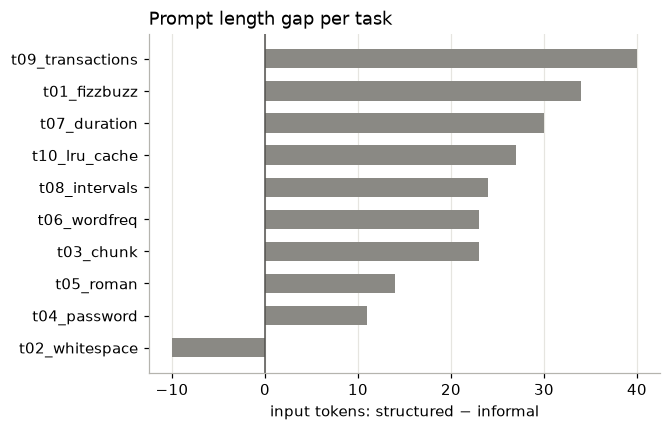

Spearman correlation between input gap and output gap across tasks: rho=0.07, p=0.854


In [9]:
inp = task_means["input_tokens"][FORMATS]
input_gap = (inp["structured"] - inp["informal"]).sort_values()
output_gap = (out["structured"] - out["informal"]).loc[input_gap.index]

fig, ax = plt.subplots(figsize=(6, 4))
ax.barh(input_gap.index, input_gap.values, color=NEUTRAL, height=0.6)
ax.axvline(0, color="#52514e", linewidth=1)
ax.set_xlabel("input tokens: structured − informal")
ax.set_title("Prompt length gap per task", loc="left")
ax.grid(axis="y", visible=False)
plt.show()

rho, p = stats.spearmanr(input_gap, output_gap)
print(f"Spearman correlation between input gap and output gap across tasks: rho={rho:.2f}, p={p:.3f}")

**How to read it:** bars to the right mean the structured prompt was longer for that task. Prompt length is a possible **confound**: if longer prompts lead to longer answers, an output difference could come from length rather than format. A strong correlation between the input gap and the output gap would point that way. With only 10 tasks, treat this as a warning sign, not proof.

**Result:** the structured prompt was longer in 9 of 10 tasks (by 11–40 tokens). The exception is `t02_whitespace`, where the informal prompt was 10 tokens *longer*, yet its answers were still 12 tokens *shorter*. Across tasks, the input gap barely tracks the output gap (Spearman ρ = 0.07, p = 0.85). Prompt length therefore doesn't appear to explain the output difference, though with 10 tasks we can't rule it out completely.

## 6. Run-to-run variability

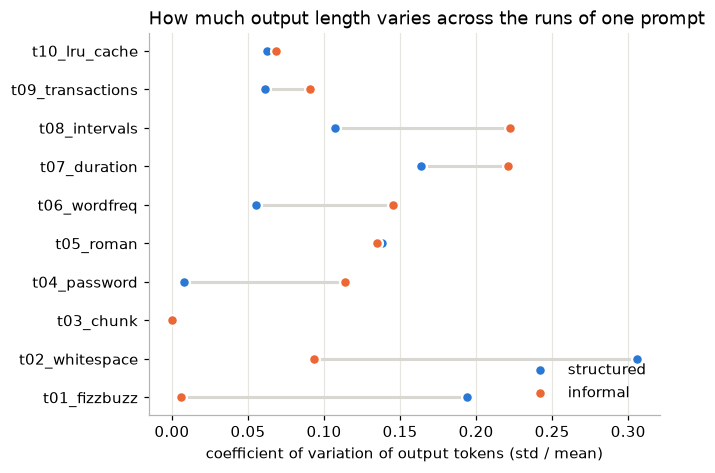

mean                 std                  cv           
format           informal structured informal structured informal structured
task_id                                                                     
t01_fizzbuzz         72.2       85.2     0.45      16.51     0.01       0.19
t02_whitespace       43.2       54.8     4.02      16.75     0.09       0.31
t03_chunk            52.0       60.0     0.00       0.00     0.00       0.00
t04_password        101.4      113.6    11.55       0.89     0.11       0.01
t05_roman           187.8      198.2    25.35      27.37     0.13       0.14
t06_wordfreq        122.0      156.0    17.69       8.60     0.15       0.06
t07_duration        220.0      208.8    48.66      34.18     0.22       0.16
t08_intervals       108.2      161.2    24.08      17.25     0.22       0.11
t09_transactions    185.2      211.2    16.81      12.95     0.09       0.06
t10_lru_cache       177.0      181.2    12.08      11.30     0.07       0.06

In [10]:
var = df.groupby(["task_id", "format"])["output_tokens"].agg(["mean", "std"])
var["cv"] = var["std"] / var["mean"]
cv = var["cv"].unstack()[FORMATS]

fig, ax = plt.subplots(figsize=(6, 4.5))
y = np.arange(len(cv))
ax.hlines(y, cv.min(axis=1), cv.max(axis=1), color="#d8d7d1", linewidth=2, zorder=1)
for f in FORMATS:
    ax.scatter(cv[f], y, s=50, color=COLORS[f], edgecolor="white", linewidth=1.5, zorder=2, label=f)
ax.set_yticks(y, cv.index)
ax.set_xlabel("coefficient of variation of output tokens (std / mean)")
ax.set_title("How much output length varies across the runs of one prompt", loc="left")
ax.grid(axis="y", visible=False)
ax.legend(frameon=False, loc="lower right")
plt.show()

var.round(2).unstack()

**How to read it:** the coefficient of variation (CV) is the standard deviation divided by the mean, so tasks with different lengths can be compared. A CV of 0.10 means runs typically differ by about 10% from their average. If one format is consistently more variable, its prompts leave the model more room to choose how much to write. High variability overall also means more runs would be needed to detect small format effects.

**Result:** there's no consistent pattern. Informal answers varied more for `t04`, `t06`, `t07`, `t08`; structured answers varied more for `t01` and `t02`. `t03_chunk` produced the *identical* answer in all 5 runs of both formats (CV = 0), so for simple tasks this model at temperature 0.7 often repeats itself. Most CVs are below 0.2, meaning run-to-run differences are typically smaller than 20% of the mean.

## 7. Output tokens vs. correctness

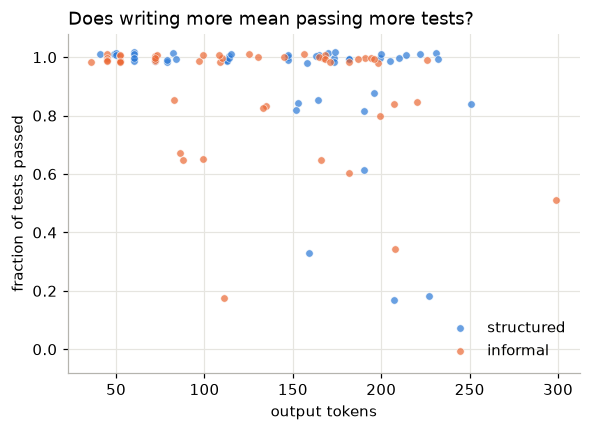

In [11]:
fig, ax = plt.subplots(figsize=(6, 4))
rng = np.random.default_rng(SEED)
for f in FORMATS:
    sub = df[df["format"] == f]
    jitter = rng.uniform(-0.02, 0.02, size=len(sub))
    ax.scatter(sub["output_tokens"], sub["pass_rate"] + jitter, s=24, color=COLORS[f],
               alpha=0.7, edgecolor="white", linewidth=0.5, label=f)
ax.set_xlabel("output tokens")
ax.set_ylabel("fraction of tests passed")
ax.set_ylim(-0.08, 1.08)
ax.set_title("Does writing more mean passing more tests?", loc="left")
ax.legend(frameon=False, loc="lower right")
plt.show()

**How to read it:** each dot is one response, with a small vertical jitter so overlapping dots stay visible. If correct answers (top row) cluster at a certain length, length and correctness are linked. If one format's dots sit lower, that format produced more failing code, and a token "saving" might just come from missing requirements.

**Result:** most responses pass every test regardless of length, and the failures are spread across short and long answers in both colors. There's no visible sign that shorter (informal) answers failed more often because they were shorter.

## 8. Output tokens per fully correct solution

In [12]:
eff = df.groupby("format").agg(
    responses=("output_tokens", "size"),
    total_output_tokens=("output_tokens", "sum"),
    fully_correct=("passed_all", "sum"),
    mean_pass_rate=("pass_rate", "mean"),
).loc[FORMATS]
eff["tokens_per_correct_solution"] = (eff["total_output_tokens"] / eff["fully_correct"]).round(1)
eff["mean_pass_rate"] = eff["mean_pass_rate"].round(3)
eff

,responses,total_output_tokens,fully_correct,mean_pass_rate,tokens_per_correct_solution
format,,,,,
structured,50,7151,40,0.926,178.8
informal,50,6345,36,0.905,176.2


**How to read it:** `tokens_per_correct_solution` is the total output tokens spent divided by the number of responses that passed every test. It combines cost and quality: a format that writes fewer tokens but fails more often can still be *less* efficient by this measure.

**Result:** structured prompts gave slightly more fully correct answers (40/50 vs 36/50; mean pass rate 0.926 vs 0.905), but used more tokens. Per fully correct solution the two formats come out nearly identical: 178.8 (structured) vs 176.2 (informal) output tokens. So informal's raw token saving is roughly cancelled by its slightly lower success rate.

## 9. Paired statistical comparison (within task)

In [13]:
def paired_comparison(metric, n_boot=10_000):
    """Compare informal vs structured using per-task means (one pair per task)."""
    means = task_means[metric][FORMATS]
    diff = means["informal"] - means["structured"]

    # Wilcoxon signed-rank: are the differences centered on 0? (Fails if every diff is 0.)
    try:
        w_stat, w_p = stats.wilcoxon(diff)
    except ValueError:
        w_stat, w_p = np.nan, np.nan

    # Bootstrap: resample the tasks with replacement and recompute the mean difference.
    rng = np.random.default_rng(SEED)
    samples = rng.choice(diff.to_numpy(), size=(n_boot, len(diff)), replace=True)
    boot_means = samples.mean(axis=1)
    ci_low, ci_high = np.percentile(boot_means, [2.5, 97.5])

    return {
        "metric": metric,
        "n_tasks": len(diff),
        "mean_diff (informal - structured)": round(diff.mean(), 3),
        "median_diff": round(diff.median(), 3),
        "bootstrap 95% CI": f"[{ci_low:.3f}, {ci_high:.3f}]",
        "wilcoxon_stat": w_stat,
        "wilcoxon_p": round(w_p, 4) if not np.isnan(w_p) else np.nan,
    }

pd.DataFrame([paired_comparison(m) for m in ["output_tokens", "input_tokens", "pass_rate"]]).set_index("metric")

,n_tasks,mean_diff (informal - structured),median_diff,bootstrap 95% CI,wilcoxon_stat,wilcoxon_p
metric,,,,,,
output_tokens,10,-16.120,-11.9,"[-27.260, -6.380]",4.0,0.0137
input_tokens,10,-21.600,-23.5,"[-29.100, -12.800]",1.0,0.0039
pass_rate,10,-0.021,0.0,"[-0.071, 0.027]",5.0,0.3125


**How to read it:**
- **mean_diff** is positive when informal prompts used more tokens (or passed more tests) than structured ones, averaged over tasks.
- **Bootstrap 95% CI:** we resample the 10 tasks 10,000 times and take the middle 95% of the resampled mean differences. If the interval excludes 0, the difference is unlikely to be just task-to-task noise.
- **Wilcoxon signed-rank p-value:** a non-parametric paired test. It asks whether the per-task differences are consistently on one side of zero, without assuming they are normally distributed.
- **Power caveat:** with only 10 pairs the test can detect only fairly consistent effects; the smallest possible two-sided p-value is about 0.002 (all 10 differences in the same direction). A non-significant result means "no evidence of a difference at this sample size", not "no difference".

**Result:** the per-task output difference is −16.1 tokens on average (informal − structured; median −11.9). The bootstrap 95% CI [−27.3, −6.4] excludes 0, and the Wilcoxon test gives p = 0.014, so informal prompts led to modestly shorter answers. Input tokens were also lower for informal (−21.6, CI [−29.1, −12.8], p = 0.004), but that's just the prompts being shorter. Pass rate shows no significant difference (−0.02, CI [−0.07, 0.03], p = 0.31).

## 9b. Where do the extra tokens go?

In [14]:
import re
import sys
from pathlib import Path

sys.path.insert(0, "../src")
from evaluate import extract_code

rows = []
safe_model = MODEL.replace(":", "-").replace("/", "-")
for path in Path("../data/raw").glob(f"*__{safe_model}.txt"):
    task_id, fmt, run, _ = path.stem.split("__")
    code_text = extract_code(path.read_text(encoding="utf-8"))
    lines = [line for line in code_text.splitlines() if line.strip()]
    rows.append({
        "format": fmt,
        "comment_lines": sum(line.strip().startswith("#") for line in lines),
        "code_lines": sum(not line.strip().startswith("#") for line in lines),
    })
pd.DataFrame(rows).groupby("format").mean().round(2).loc[FORMATS]

,comment_lines,code_lines
format,,
structured,0.80,13.8
informal,0.08,13.0


**How to read it:** this reads the saved raw answers (`data/raw/`, not committed to git, so it needs a local run) and counts comment lines and code lines per answer.

**Result:** structured answers averaged 0.8 comment lines vs 0.1 for informal, plus slightly more code (13.8 vs 13.0 non-comment lines). Neither format got prose explanations or usage examples, so the model followed "only Python code" in both. Part of the extra length from structured prompts is comments, perhaps mirroring the labeled, list-like requirements; the rest is slightly more code.

## 10. Conclusions and limitations

**Conclusions:** for `qwen2.5-coder:7b`, informal prompts led to modestly but consistently shorter answers: about 16 fewer output tokens per task (≈11%), shorter in 9 of 10 tasks, 95% CI [−27, −6], Wilcoxon p = 0.014. The informal prompts were also shorter to send, but the size of that gap doesn't track the output difference across tasks, so prompt length doesn't seem to be the explanation. Correctness didn't differ significantly, but structured prompts produced slightly more fully correct solutions (40 vs 36 of 50). Measured as output tokens per *fully correct* solution, the two formats are essentially tied (~177–179). In short, informal prompting saved tokens per call without a clear quality cost in this sample, but the saving roughly disappears once failed attempts are counted.

**Limitations to discuss:**
- **One model** (`qwen2.5-coder:7b`, a small open-source model run locally) at one temperature; results may not carry over to larger commercial models (e.g. Claude, GPT) or to other temperatures.
- **One prompt pair per task:** the specific wording of each informal paragraph is mixed in with "informality" itself. More paraphrases per format would separate the two.
- **Small sample:** 10 tasks means low statistical power and wide confidence intervals.
- **Prompt length differs between formats** (section 5), which is a possible confound.
- **Small, self-contained tasks:** real-world coding prompts are longer and messier.